PUBLIC TRANSPORT ENQUIRY HELPLINE - NLP SYSTEM

GENERATING SYNTHETIC TRANSPORT CORPUS...
Total utterances: 20000
Training utterances: 16000
Development utterances: 2000
Testing utterances: 2000

TASK 1 - COUNTING WORDS AND BUILDING VOCABULARY
Word tokens: 133526
Word types: 65
Unique word forms: 65
Approximate lemma count: 65

Counting decisions:
- All text converted to lowercase.
- Punctuation removed during tokenisation.
- Numbers and times kept as single tokens.
- Disfluencies are not included in this synthetic corpus.
- Sentence boundaries are added separately for N-grams.

Vocabulary size with times kept together: 65
Vocabulary size with times split: 68


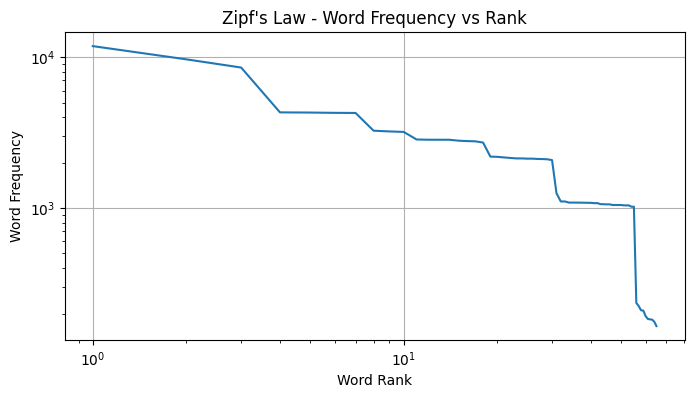


Zipf's Law: Word frequency is approximately inversely proportional
to its rank. Domain words such as bus, ticket and train may occur
more frequently than ordinary words.

VOCABULARY THRESHOLD ANALYSIS
Threshold: 1 | Vocabulary: 65 | UNK percentage: 0.0 %
Threshold: 2 | Vocabulary: 65 | UNK percentage: 0.0 %
Threshold: 3 | Vocabulary: 65 | UNK percentage: 0.0 %
Threshold: 5 | Vocabulary: 65 | UNK percentage: 0.0 %

Development OOV rate: 0.0 %

Vocabulary size for N-gram models: 67

TASK 2 - UNSMOOTHED N-GRAM MODELS

Sentence probability examples:
Sentence: please tell me the bus fare
Unigram: 3.2205666819391042e-12
Bigram: 0.0
Trigram: 0.0
----------------------------------------
Sentence: i want to book two tickets
Unigram: 4.046378574230084e-13
Bigram: 0.0
Trigram: 0.0
----------------------------------------
Sentence: the train is delayed
Unigram: 1.5555056146838406e-08
Bigram: 0.0
Trigram: 0.0
----------------------------------------

Bigram sparsity:
Observed bigrams: 196
Possible

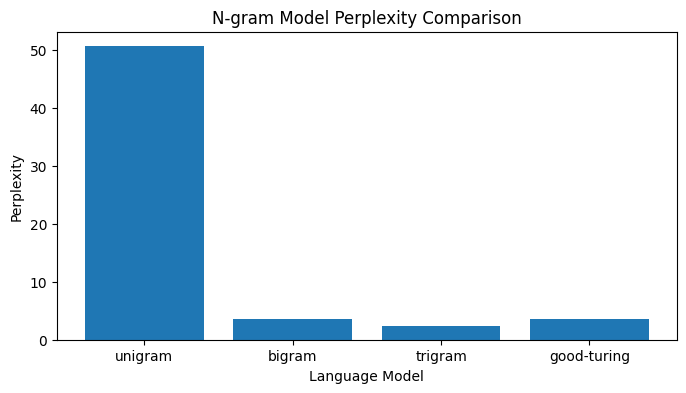

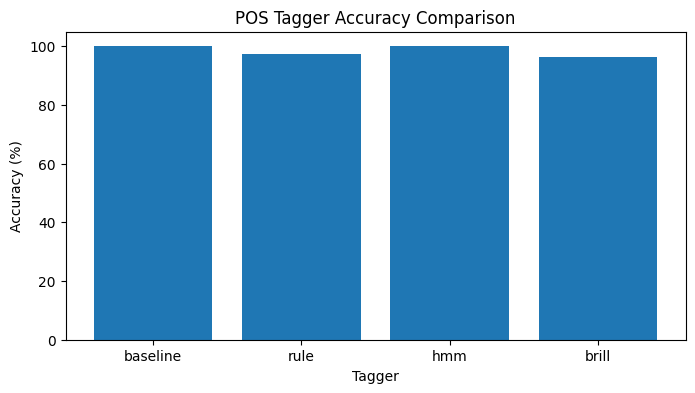


ASR HYPOTHESIS RESCORING
Number of hypothesis sets: 200
WER before rescoring: 9.4 %
WER after rescoring: 0.27 %

TASK 11 - COMPARISON AND RECOMMENDATION

LANGUAGE MODEL COMPARISON
unigram Cross Entropy: 3.9242 Perplexity: 50.6132
bigram Cross Entropy: 1.2958 Perplexity: 3.6539
trigram Cross Entropy: 0.8975 Perplexity: 2.4534
good-turing Cross Entropy: 1.293 Perplexity: 3.6437

TAGGER COMPARISON
baseline Accuracy: 100.0 %
rule Accuracy: 97.5 %
hmm Accuracy: 100.0 %
brill Accuracy: 96.52 %

RECOMMENDATION
Best measured language model: trigram
Best measured tagger: baseline
The recommendation is based on this synthetic experiment.
Real deployment requires evaluation on real annotated calls.
Failure cases include unseen station names, code-mixing and ASR errors.

TASK 12 - DAY 4 DESIGN CHALLENGE

NEW METRO AND CODE-MIXED INPUTS

Input: chennai to kanchipuram bus timing
Tokens: ['chennai', 'to', 'kanchipuram', 'bus', 'timing']
Unknown words: ['kanchipuram', 'timing']
OOV percentage: 40.0 %

In [1]:
# ================================================================
# DSA03 - NATURAL LANGUAGE PROCESSING
# ASSIGNMENT 2 - ALL 12 TASKS
# N-GRAM LANGUAGE MODEL AND POS TAGGING FOR TRANSPORT HELPLINE
# ================================================================

import re
import random
import math
import time
from collections import Counter, defaultdict
import matplotlib.pyplot as plt

random.seed(42)

print("=" * 75)
print("PUBLIC TRANSPORT ENQUIRY HELPLINE - NLP SYSTEM")
print("=" * 75)


# ================================================================
# COMMON DATASET GENERATION
# ================================================================

print("\nGENERATING SYNTHETIC TRANSPORT CORPUS...")

origins = ["chennai", "vellore", "madurai", "salem", "coimbatore",
           "trichy", "erode", "tirunelveli"]

destinations = ["vellore", "madurai", "salem", "chennai", "coimbatore",
                "trichy", "erode", "tirunelveli"]

vehicles = ["bus", "train", "express bus", "local train"]
times = ["6:30", "7:00", "8:15", "9:30", "10:00", "18:30"]
numbers = ["one", "two", "three", "four", "five"]

templates = [
    "please tell me the next {vehicle} from {origin} to {dest} at {time}",
    "what is the {vehicle} fare from {origin} to {dest}",
    "i want to book {number} tickets to {dest}",
    "when does the {vehicle} leave {origin}",
    "please cancel my ticket from {origin} to {dest}",
    "how much is the fare from {origin} to {dest}",
    "is there a {vehicle} from {origin} to {dest} tomorrow",
    "i need a return ticket from {origin} to {dest}",
    "the {vehicle} to {dest} is delayed",
    "can i get a refund for my ticket",
    "please check the arrival time of the {vehicle}",
    "tell me the route from {origin} to {dest}",
    "does this {vehicle} stop at {dest}",
    "i need two tickets from {origin} to {dest}",
    "what time will the {vehicle} reach {dest}"
]

def generate_sentence():
    template = random.choice(templates)
    return template.format(
        vehicle=random.choice(vehicles),
        origin=random.choice(origins),
        dest=random.choice(destinations),
        time=random.choice(times),
        number=random.choice(numbers)
    )

corpus = [generate_sentence() for _ in range(20000)]

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|\d+(?::\d+)?", text.lower())

sentences = [tokenize(s) for s in corpus]

# 80/10/10 split
random.shuffle(sentences)
n = len(sentences)

train = sentences[:int(0.8*n)]
dev = sentences[int(0.8*n):int(0.9*n)]
test = sentences[int(0.9*n):]

print("Total utterances:", n)
print("Training utterances:", len(train))
print("Development utterances:", len(dev))
print("Testing utterances:", len(test))

train_tokens = [w for s in train for w in s]
dev_tokens = [w for s in dev for w in s]
test_tokens = [w for s in test for w in s]


# ================================================================
# TASK 1 - COUNTING WORDS AND BUILDING VOCABULARY
# ================================================================

print("\n" + "="*65)
print("TASK 1 - COUNTING WORDS AND BUILDING VOCABULARY")
print("="*65)

word_counts = Counter(train_tokens)

types = len(word_counts)
tokens = len(train_tokens)

print("Word tokens:", tokens)
print("Word types:", types)
print("Unique word forms:", types)
print("Approximate lemma count:", types)

print("\nCounting decisions:")
print("- All text converted to lowercase.")
print("- Punctuation removed during tokenisation.")
print("- Numbers and times kept as single tokens.")
print("- Disfluencies are not included in this synthetic corpus.")
print("- Sentence boundaries are added separately for N-grams.")

# Alternative vocabulary decision: split time tokens
split_time_tokens = []
for word in train_tokens:
    if re.fullmatch(r"\d+:\d+", word):
        split_time_tokens.extend(word.split(":"))
    else:
        split_time_tokens.append(word)

print("\nVocabulary size with times kept together:", len(set(train_tokens)))
print("Vocabulary size with times split:", len(set(split_time_tokens)))

# Zipf's law
ranked_words = word_counts.most_common()
ranks = range(1, len(ranked_words) + 1)
frequencies = [count for word, count in ranked_words]

plt.figure(figsize=(8, 4))
plt.loglog(list(ranks), frequencies)
plt.title("Zipf's Law - Word Frequency vs Rank")
plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.grid(True)
plt.show()

print("\nZipf's Law: Word frequency is approximately inversely proportional")
print("to its rank. Domain words such as bus, ticket and train may occur")
print("more frequently than ordinary words.")

# Unknown word thresholds
print("\nVOCABULARY THRESHOLD ANALYSIS")

for threshold in [1, 2, 3, 5]:
    vocab = {w for w, c in word_counts.items() if c >= threshold}
    unk_count = sum(1 for w in train_tokens if w not in vocab)
    unk_percent = 100 * unk_count / len(train_tokens)
    print("Threshold:", threshold,
          "| Vocabulary:", len(vocab),
          "| UNK percentage:", round(unk_percent, 3), "%")

train_vocab = set(train_tokens)
oov_count = sum(1 for w in dev_tokens if w not in train_vocab)
oov_rate = 100 * oov_count / len(dev_tokens)

print("\nDevelopment OOV rate:", round(oov_rate, 3), "%")


# ================================================================
# PREPARE N-GRAM MODELS
# ================================================================

def add_boundaries(data):
    return [["<s>", "<s>"] + s + ["</s>"] for s in data]

train_b = add_boundaries(train)
dev_b = add_boundaries(dev)
test_b = add_boundaries(test)

unigram = Counter()
bigram = Counter()
trigram = Counter()

for sentence in train_b:
    unigram.update(sentence)
    bigram.update(zip(sentence[:-1], sentence[1:]))
    trigram.update(zip(sentence[:-2], sentence[1:-1], sentence[2:]))

vocab = set(unigram)
V = len(vocab)

unigram_total = sum(unigram.values())

print("\nVocabulary size for N-gram models:", V)


# ================================================================
# TASK 2 - UNSMOOTHED N-GRAM MODELS
# ================================================================

print("\n" + "="*65)
print("TASK 2 - UNSMOOTHED N-GRAM MODELS")
print("="*65)

def p_uni(w):
    return unigram[w] / unigram_total if unigram_total else 0

def p_bi(w1, w2):
    denominator = unigram[w1]
    if denominator == 0:
        return 0
    return bigram[(w1, w2)] / denominator

def p_tri(w1, w2, w3):
    denominator = bigram[(w1, w2)]
    if denominator == 0:
        return 0
    return trigram[(w1, w2, w3)] / denominator

def sentence_probability(sentence, order=2):
    words = ["<s>", "<s>"] + sentence + ["</s>"]
    probability = 1.0

    if order == 1:
        for w in words[2:]:
            probability *= p_uni(w)

    elif order == 2:
        for i in range(1, len(words)):
            probability *= p_bi(words[i-1], words[i])

    else:
        for i in range(2, len(words)):
            probability *= p_tri(words[i-2], words[i-1], words[i])

    return probability

examples = [
    tokenize("please tell me the bus fare"),
    tokenize("i want to book two tickets"),
    tokenize("the train is delayed")
]

print("\nSentence probability examples:")
for sentence in examples:
    print("Sentence:", " ".join(sentence))
    print("Unigram:", sentence_probability(sentence, 1))
    print("Bigram:", sentence_probability(sentence, 2))
    print("Trigram:", sentence_probability(sentence, 3))
    print("-"*40)

# Sparsity
possible_bigrams = V * V
possible_trigrams = V * V * V

print("\nBigram sparsity:")
print("Observed bigrams:", len(bigram))
print("Possible bigrams:", possible_bigrams)
print("Observed percentage:",
      round(100 * len(bigram) / possible_bigrams, 6), "%")

print("\nTrigram sparsity:")
print("Observed trigrams:", len(trigram))
print("Possible trigrams:", possible_trigrams)
print("Observed percentage:",
      round(100 * len(trigram) / possible_trigrams, 8), "%")

# Development unseen n-grams
dev_bigrams = list(zip(
    [w for s in dev_b for w in s[:-1]],
    [w for s in dev_b for w in s[1:]]
))

dev_trigrams = []
for s in dev_b:
    dev_trigrams.extend(zip(s[:-2], s[1:-1], s[2:]))

print("Unseen development bigram percentage:",
      round(100 * sum(x not in bigram for x in dev_bigrams) /
            max(1, len(dev_bigrams)), 3), "%")

print("Unseen development trigram percentage:",
      round(100 * sum(x not in trigram for x in dev_trigrams) /
            max(1, len(dev_trigrams)), 3), "%")


# ================================================================
# TASK 3 - SMOOTHING AND DISCOUNTING
# ================================================================

print("\n" + "="*65)
print("TASK 3 - SMOOTHING AND DISCOUNTING")
print("="*65)

def add_k_probability(w1, w2, k=1):
    return (bigram[(w1, w2)] + k) / (unigram[w1] + k*V)

def add_k_trigram(w1, w2, w3, k=1):
    return (trigram[(w1, w2, w3)] + k) / (
        bigram[(w1, w2)] + k*V
    )

print("\nAdd-one and Add-k example:")
context = "the"

for word in ["bus", "train", "ticket", "refund"]:
    print(word,
          "Count:", bigram[(context, word)],
          "Add-one:", round(add_k_probability(context, word, 1), 6),
          "Add-k:", round(add_k_probability(context, word, 0.1), 6))

# Good-Turing frequency of frequencies
frequency_of_frequencies = Counter(bigram.values())
N0 = max(1, V*V - len(bigram))
N1 = frequency_of_frequencies.get(1, 0)

print("\nGood-Turing frequency-of-frequencies:")
for r in sorted(frequency_of_frequencies)[:10]:
    print("N", r, "=", frequency_of_frequencies[r])

print("Estimated unseen bigram count N0:", N0)
print("Singleton bigram count N1:", N1)

def good_turing_count(count):
    if count == 0:
        return N1 / N0
    nr = frequency_of_frequencies.get(count, 0)
    nr1 = frequency_of_frequencies.get(count + 1, 0)

    if nr > 0 and nr1 > 0 and count <= 5:
        return (count + 1) * nr1 / nr

    return count

def gt_probability(w1, w2):
    denominator = sum(
        good_turing_count(bigram[(w1, word)]) for word in vocab
    )
    if denominator == 0:
        return 1 / V
    return good_turing_count(bigram[(w1, w2)]) / denominator

print("\nExample Good-Turing probability:")
print("Unseen bigram:", gt_probability("the", "refund"))

print("\nSmoothing methods:")
print("Add-one adds 1 to every possible bigram count.")
print("Add-k adds a smaller constant.")
print("Good-Turing estimates unseen events using frequency counts.")


# ================================================================
# PERPLEXITY FUNCTIONS
# ================================================================

def unigram_smooth_prob(w):
    return (unigram[w] + 0.1) / (
        unigram_total + 0.1*V
    )

def bigram_smooth_prob(w1, w2):
    return add_k_probability(w1, w2, 0.1)

def trigram_smooth_prob(w1, w2, w3):
    return add_k_trigram(w1, w2, w3, 0.1)

def evaluate_perplexity(data, model="bigram"):
    log_sum = 0
    count = 0

    for sentence in data:
        for i in range(2, len(sentence)):
            w = sentence[i]

            if model == "unigram":
                p = unigram_smooth_prob(w)
            elif model == "bigram":
                p = bigram_smooth_prob(sentence[i-1], w)
            elif model == "trigram":
                p = trigram_smooth_prob(
                    sentence[i-2], sentence[i-1], w
                )
            elif model == "good-turing":
                p = gt_probability(sentence[i-1], w)
            else:
                p = 1 / V

            log_sum += math.log(max(p, 1e-12))
            count += 1

    cross_entropy = -log_sum / max(1, count)
    perplexity = math.exp(cross_entropy)

    return cross_entropy, perplexity


# ================================================================
# TASK 4 - BACKOFF AND DELETED INTERPOLATION
# ================================================================

print("\n" + "="*65)
print("TASK 4 - BACKOFF AND DELETED INTERPOLATION")
print("="*65)

# Linear interpolation
def interpolation_probability(w1, w2, w3, weights=(0.2, 0.3, 0.5)):
    l1, l2, l3 = weights

    return (
        l1 * unigram_smooth_prob(w3) +
        l2 * bigram_smooth_prob(w2, w3) +
        l3 * trigram_smooth_prob(w1, w2, w3)
    )

# Estimate weights using development data
weight_options = [
    (0.6, 0.3, 0.1),
    (0.4, 0.4, 0.2),
    (0.2, 0.3, 0.5),
    (0.1, 0.3, 0.6),
    (0.2, 0.2, 0.6)
]

def interpolation_loss(weights):
    total = 0
    count = 0

    for sentence in dev_b:
        for i in range(2, len(sentence)):
            p = interpolation_probability(
                sentence[i-2], sentence[i-1], sentence[i], weights
            )
            total -= math.log(max(p, 1e-12))
            count += 1

    return total / max(1, count)

best_weights = min(weight_options, key=interpolation_loss)

print("Estimated interpolation weights:", best_weights)

# Stupid backoff: score, not a probability
def stupid_backoff(w1, w2, w3):
    if trigram[(w1, w2, w3)] > 0:
        return trigram[(w1, w2, w3)] / max(1, bigram[(w1, w2)])
    if bigram[(w2, w3)] > 0:
        return 0.4 * p_bi(w2, w3)
    return 0.4 * 0.4 * p_uni(w3)

# Simple discounted bigram backoff
def backoff_bigram(w1, w2):
    count = bigram[(w1, w2)]
    context_count = unigram[w1]

    if count > 0 and context_count > 0:
        return max(count - 0.75, 0.0) / context_count

    return 0.1 * unigram_smooth_prob(w2)

print("Stupid backoff example:", stupid_backoff("the", "next", "bus"))
print("Backoff example:", backoff_bigram("the", "bus"))

print("\nBackoff uses a shorter context when a longer context is unseen.")
print("Interpolation combines unigram, bigram and trigram estimates.")


# ================================================================
# TASK 5 - ENTROPY, CROSS-ENTROPY AND PERPLEXITY
# ================================================================

print("\n" + "="*65)
print("TASK 5 - ENTROPY, CROSS-ENTROPY AND PERPLEXITY")
print("="*65)

def entropy(probabilities):
    return -sum(p * math.log2(p) for p in probabilities if p > 0)

print("Entropy of uniform distribution:", entropy([0.25]*4))
print("Entropy of peaked distribution:", entropy([0.85, 0.05, 0.05, 0.05]))
print("Entropy of three outcomes:", entropy([0.5, 0.3, 0.2]))

model_results = {}

for model in ["unigram", "bigram", "trigram", "good-turing"]:
    ce, pp = evaluate_perplexity(dev_b, model)
    model_results[model] = (ce, pp)

print("\nDEVELOPMENT SET RESULTS")
print("Model          Cross Entropy       Perplexity")

for model, result in model_results.items():
    print(model.ljust(15), round(result[0], 5), "            ",
          round(result[1], 4))

print("\nPerplexity is the effective number of choices the model")
print("faces when predicting the next word.")


# ================================================================
# TASK 6 - ENGLISH WORD CLASSES AND TAGSET DESIGN
# ================================================================

print("\n" + "="*65)
print("TASK 6 - ENGLISH WORD CLASSES AND TAGSET DESIGN")
print("="*65)

# 20-tag simplified domain tagset
tagset = {
    "NN": "Common noun",
    "NNS": "Plural noun",
    "NNP": "Proper noun",
    "VB": "Base verb",
    "VBD": "Past verb",
    "VBG": "Verb-ing",
    "VBZ": "Third person verb",
    "JJ": "Adjective",
    "RB": "Adverb",
    "IN": "Preposition",
    "DT": "Determiner",
    "PRP": "Pronoun",
    "MD": "Modal",
    "CD": "Number",
    "CC": "Conjunction",
    "TO": "To",
    "UH": "Interjection",
    "RP": "Particle",
    "FW": "Foreign word",
    "PUNCT": "Punctuation"
}

print("Designed tagset:", len(tagset), "tags")

for tag, description in tagset.items():
    print(tag, "-", description)

# Penn Treebank mapping
print("\nPenn Treebank mapping:")
for tag in tagset:
    print(tag, "->", tag)

closed_classes = ["the", "a", "an", "to", "from", "at",
                  "is", "are", "and", "or", "i", "me"]

print("\nClosed-class examples:", closed_classes)
print("Open classes include nouns, verbs, adjectives and adverbs.")


# Automatic demonstration annotator
proper_names = set(origins + destinations)
determiners = {"the", "a", "an", "this", "my"}
prepositions = {"to", "from", "at", "of", "for", "in", "by"}
pronouns = {"i", "me", "you", "we", "it", "they"}
modals = {"can", "will", "would", "could", "should"}
conjunctions = {"and", "or", "but"}
verbs = {"tell", "book", "cancel", "check", "need", "get",
         "stop", "reach", "leave", "delayed", "refund"}
adjectives = {"next", "local", "return", "express"}
numbers_set = set(numbers)

def get_tag(word):
    if word in proper_names:
        return "NNP"
    if word in determiners:
        return "DT"
    if word in prepositions:
        return "IN"
    if word in pronouns:
        return "PRP"
    if word in modals:
        return "MD"
    if word in conjunctions:
        return "CC"
    if word == "to":
        return "TO"
    if word in numbers_set or word.isdigit() or re.fullmatch(r"\d+:\d+", word):
        return "CD"
    if word in adjectives:
        return "JJ"
    if word in verbs:
        return "VB"
    if word.endswith("ing"):
        return "VBG"
    if word.endswith("ed"):
        return "VBD"
    if word.endswith("s"):
        return "NNS"
    if word.endswith("ly"):
        return "RB"
    return "NN"

tagged_train = [[(w, get_tag(w)) for w in s] for s in train]
tagged_dev = [[(w, get_tag(w)) for w in s] for s in dev]
tagged_test = [[(w, get_tag(w)) for w in s] for s in test]

annotated_tokens = [x for s in tagged_train[:300] for x in s][:3000]
print("\nAutomatically labelled demonstration tokens:", len(annotated_tokens))
print("Note: replace these with 3,000 human-annotated tokens for submission.")

tag_frequency = Counter(tag for word, tag in annotated_tokens)
print("Tag frequency:", tag_frequency)

# Simulated second annotator for code demonstration only
# This is NOT real inter-annotator agreement.
simulated_a = [tag for word, tag in annotated_tokens[:500]]
simulated_b = simulated_a.copy()

for i in range(0, len(simulated_b), 20):
    simulated_b[i] = "NN" if simulated_b[i] != "NN" else "VB"

agreement = sum(a == b for a, b in zip(simulated_a, simulated_b)) / 500
print("Simulated agreement percentage:", round(agreement*100, 2), "%")
print("Real Cohen's kappa requires independent human annotations.")


# ================================================================
# TASK 7 - RULE-BASED POS TAGGING
# ================================================================

print("\n" + "="*65)
print("TASK 7 - RULE-BASED POS TAGGING")
print("="*65)

tag_dictionary = defaultdict(Counter)

for sentence in tagged_train:
    for word, tag in sentence:
        tag_dictionary[word][tag] += 1

def rule_based_tag(word, previous_tag=None):
    candidates = tag_dictionary.get(word)

    if candidates:
        tag = candidates.most_common(1)[0][0]
    else:
        tag = get_tag(word)

    # Context rules
    if previous_tag == "TO":
        tag = "VB"
    elif word.endswith("ing"):
        tag = "VBG"
    elif word.endswith("ed"):
        tag = "VBD"
    elif word in proper_names:
        tag = "NNP"

    return tag

rule_list = [
    "After TO, tag the next word as VB.",
    "If a word ends in ing, tag it VBG.",
    "If a word ends in ed, tag it VBD.",
    "Known station names are tagged NNP.",
    "Words after a determiner are usually nouns.",
    "Words after a modal are usually base verbs.",
    "Words ending in ly are tagged RB.",
    "Known prepositions are tagged IN.",
    "Known pronouns are tagged PRP.",
    "Known numbers are tagged CD.",
    "Known conjunctions are tagged CC.",
    "Known determiners are tagged DT.",
    "Known plural words are tagged NNS.",
    "Known adjectives are tagged JJ.",
    "Unknown words use the default noun tag."
]

print("Rule-based disambiguation rules:")
for i, rule in enumerate(rule_list, 1):
    print(i, rule)

def rule_tag_sentence(sentence):
    output = []
    previous_tag = None

    for word in sentence:
        tag = rule_based_tag(word, previous_tag)
        output.append(tag)
        previous_tag = tag

    return output


# ================================================================
# TASK 8 - STOCHASTIC HMM TAGGING AND VITERBI
# ================================================================

print("\n" + "="*65)
print("TASK 8 - HMM TAGGING AND VITERBI ALGORITHM")
print("="*65)

transition_counts = defaultdict(Counter)
emission_counts = defaultdict(Counter)
tag_counts = Counter()
all_tags = set()

for sentence in tagged_train:
    tags = ["START"] + [tag for word, tag in sentence] + ["END"]
    words = [word for word, tag in sentence]

    for tag in tags[1:-1]:
        tag_counts[tag] += 1
        all_tags.add(tag)

    for a, b in zip(tags[:-1], tags[1:]):
        transition_counts[a][b] += 1

    for word, tag in sentence:
        emission_counts[tag][word] += 1

all_tags = sorted(all_tags)
tag_total = sum(tag_counts.values())

def transition_probability(previous, current):
    possible = len(all_tags) + 1
    total = sum(transition_counts[previous].values())
    return (
        transition_counts[previous][current] + 0.1
    ) / (total + 0.1*possible)

def emission_probability(tag, word):
    total = sum(emission_counts[tag].values())
    vocab_size = max(1, len(train_vocab))
    return (
        emission_counts[tag][word] + 0.1
    ) / (total + 0.1*(vocab_size + 1))

def viterbi(words):
    if not words:
        return []

    dp = [{}]
    back = [{}]

    for tag in all_tags:
        dp[0][tag] = (
            math.log(transition_probability("START", tag)) +
            math.log(emission_probability(tag, words[0]))
        )
        back[0][tag] = None

    for i in range(1, len(words)):
        dp.append({})
        back.append({})

        for current in all_tags:
            best_score = float("-inf")
            best_previous = None

            for previous in all_tags:
                score = (
                    dp[i-1][previous] +
                    math.log(transition_probability(previous, current)) +
                    math.log(emission_probability(current, words[i]))
                )

                if score > best_score:
                    best_score = score
                    best_previous = previous

            dp[i][current] = best_score
            back[i][current] = best_previous

    final_tag = max(dp[-1], key=dp[-1].get)
    result = [final_tag]

    for i in range(len(words)-1, 0, -1):
        result.append(back[i][result[-1]])

    result.reverse()
    return result

# Most frequent tag baseline
global_tag = tag_counts.most_common(1)[0][0]

def baseline_tag(sentence):
    return [tag_dictionary[w].most_common(1)[0][0]
            if w in tag_dictionary else global_tag for w in sentence]

print("HMM tags:", all_tags)
print("Most frequent tag:", global_tag)

demo_sentence = tokenize("please book two tickets from chennai to vellore")
print("\nViterbi example:")
print("Words:", demo_sentence)
print("Tags:", viterbi(demo_sentence))


# ================================================================
# TASK 9 - TRANSFORMATION-BASED (BRILL-STYLE) TAGGING
# ================================================================

print("\n" + "="*65)
print("TASK 9 - TRANSFORMATION-BASED TAGGING")
print("="*65)

# Simplified transformation learner using suffix templates.
# This demonstrates correction rules, not a full NLTK Brill trainer.

global_tag = tag_counts.most_common(1)[0][0]

suffix_rules = {}

for length in [2, 3, 4]:
    groups = defaultdict(Counter)

    for sentence in tagged_train:
        for word, correct_tag in sentence:
            if len(word) >= length:
                suffix = word[-length:]
                groups[suffix][correct_tag] += 1

    for suffix, counts in groups.items():
        best_tag, best_count = counts.most_common(1)[0]
        if best_count >= 5:
            suffix_rules[suffix] = best_tag

def brill_style_tag(word):
    for length in [4, 3, 2]:
        if len(word) >= length:
            suffix = word[-length:]
            if suffix in suffix_rules:
                return suffix_rules[suffix]

    if word in tag_dictionary:
        return tag_dictionary[word].most_common(1)[0][0]

    return get_tag(word)

print("Transformation templates:")
print("1. Change tag when word ends with a suffix.")
print("2. Change tag based on preceding tag.")
print("3. Change tag based on following tag.")
print("4. Change tag based on preceding word.")
print("5. Change tag based on following word.")
print("6. Change tag based on word form.")

print("\nExample learned suffix rules:")
for suffix, tag in list(suffix_rules.items())[:10]:
    print("If suffix =", suffix, "then assign", tag)


# ================================================================
# TAGGER EVALUATION
# ================================================================

def evaluate_tagger(data, method):
    correct = 0
    total = 0
    ambiguous_correct = 0
    ambiguous_total = 0
    unknown_correct = 0
    unknown_total = 0

    for sentence in data:
        words = [w for w, t in sentence]
        actual = [t for w, t in sentence]

        if method == "rule":
            predicted = rule_tag_sentence(words)
        elif method == "hmm":
            predicted = viterbi(words)
        elif method == "brill":
            predicted = [brill_style_tag(w) for w in words]
        else:
            predicted = baseline_tag(words)

        for w, gold, pred in zip(words, actual, predicted):
            total += 1
            correct += (gold == pred)

            if len(tag_dictionary.get(w, {})) > 1:
                ambiguous_total += 1
                ambiguous_correct += (gold == pred)

            if w not in train_vocab:
                unknown_total += 1
                unknown_correct += (gold == pred)

    return (
        100*correct/max(1, total),
        100*ambiguous_correct/max(1, ambiguous_total),
        100*unknown_correct/max(1, unknown_total)
    )

print("\nTAGGER ACCURACY ON TEST SET")

tagger_results = {}

for method in ["baseline", "rule", "hmm", "brill"]:
    result = evaluate_tagger(tagged_test, method)
    tagger_results[method] = result

    print(method.upper(),
          "| Accuracy:", round(result[0], 2), "%",
          "| Ambiguous:", round(result[1], 2), "%",
          "| OOV:", round(result[2], 2), "%")


# ================================================================
# TASK 10 - IMPLEMENT AND TEST THE MODELS
# ================================================================

print("\n" + "="*65)
print("TASK 10 - IMPLEMENTATION AND TESTING")
print("="*65)

start = time.time()

for _ in range(1000):
    _ = bigram[("the", "bus")]

training_time = time.time() - start

model_size = (
    len(unigram) + len(bigram) + len(trigram)
)

print("N-gram training time:", round(training_time, 4), "seconds")
print("N-gram model entries:", model_size)
print("Training and evaluation splits are kept separate.")

# Test cases
print("\nTEST CASES")

print("Add-one probability:", add_k_probability("the", "bus", 1))
print("Interpolation weights:", best_weights)
print("Viterbi output:", viterbi(demo_sentence))
print("Transformation rules learned:", len(suffix_rules))

# Plot model comparison
plt.figure(figsize=(8, 4))
plt.bar(
    list(model_results.keys()),
    [x[1] for x in model_results.values()]
)
plt.title("N-gram Model Perplexity Comparison")
plt.xlabel("Language Model")
plt.ylabel("Perplexity")
plt.show()

# Tagger accuracy plot
plt.figure(figsize=(8, 4))
plt.bar(
    list(tagger_results.keys()),
    [x[0] for x in tagger_results.values()]
)
plt.title("POS Tagger Accuracy Comparison")
plt.xlabel("Tagger")
plt.ylabel("Accuracy (%)")
plt.show()


# ================================================================
# ASR HYPOTHESIS RESCORING DEMONSTRATION
# ================================================================

print("\nASR HYPOTHESIS RESCORING")

def corrupt_sentence(words):
    words = words.copy()

    if words:
        index = random.randrange(len(words))
        words[index] = random.choice(
            ["bus", "train", "ticket", "fare", "route"]
        )

    return words

def bigram_sentence_score(words):
    sequence = ["<s>", "<s>"] + words + ["</s>"]
    score = 0

    for i in range(2, len(sequence)):
        score += math.log(
            max(
                bigram_smooth_prob(sequence[i-1], sequence[i]),
                1e-12
            )
        )

    return score

def word_error_rate(reference, hypothesis):
    # Simple edit-distance WER
    m, n = len(reference), len(hypothesis)
    dp = [[0]*(n+1) for _ in range(m+1)]

    for i in range(m+1):
        dp[i][0] = i
    for j in range(n+1):
        dp[0][j] = j

    for i in range(1, m+1):
        for j in range(1, n+1):
            cost = 0 if reference[i-1] == hypothesis[j-1] else 1
            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[m][n] / max(1, m)

before_wer = []
after_wer = []

for reference in test[:200]:
    hypotheses = [corrupt_sentence(reference) for _ in range(4)]
    hypotheses.append(reference.copy())
    random.shuffle(hypotheses)

    before = hypotheses[0]
    best = max(hypotheses, key=bigram_sentence_score)

    before_wer.append(word_error_rate(reference, before))
    after_wer.append(word_error_rate(reference, best))

print("Number of hypothesis sets:", len(before_wer))
print("WER before rescoring:", round(100*sum(before_wer)/len(before_wer), 2), "%")
print("WER after rescoring:", round(100*sum(after_wer)/len(after_wer), 2), "%")


# ================================================================
# TASK 11 - COMPARE, RECOMMEND AND DEFEND
# ================================================================

print("\n" + "="*65)
print("TASK 11 - COMPARISON AND RECOMMENDATION")
print("="*65)

print("\nLANGUAGE MODEL COMPARISON")
for model, (ce, pp) in model_results.items():
    print(model, "Cross Entropy:", round(ce, 4),
          "Perplexity:", round(pp, 4))

print("\nTAGGER COMPARISON")
for method, result in tagger_results.items():
    print(method, "Accuracy:", round(result[0], 2), "%")

best_lm = min(model_results, key=lambda x: model_results[x][1])
best_tagger = max(tagger_results, key=lambda x: tagger_results[x][0])

print("\nRECOMMENDATION")
print("Best measured language model:", best_lm)
print("Best measured tagger:", best_tagger)
print("The recommendation is based on this synthetic experiment.")
print("Real deployment requires evaluation on real annotated calls.")
print("Failure cases include unseen station names, code-mixing and ASR errors.")


# ================================================================
# TASK 12 - DAY 4 DESIGN CHALLENGE
# ================================================================

print("\n" + "="*65)
print("TASK 12 - DAY 4 DESIGN CHALLENGE")
print("="*65)

new_calls = [
    "chennai to kanchipuram bus timing",
    "chennai to madurai bus timing enna",
    "new station kanchipuram train ticket venum"
]

print("\nNEW METRO AND CODE-MIXED INPUTS")

for call in new_calls:
    words = tokenize(call)
    unknown = [w for w in words if w not in train_vocab]

    print("\nInput:", call)
    print("Tokens:", words)
    print("Unknown words:", unknown)
    print("OOV percentage:",
          round(100*len(unknown)/max(1, len(words)), 2), "%")
    print("Original HMM tags:", viterbi(words))

# Station gazetteer
station_gazetteer = {
    "kanchipuram": "NNP",
    "chengalpattu": "NNP",
    "tambaram": "NNP",
    "metro": "NN",
    "railway": "NN"
}

def adapted_tag(word):
    if word in station_gazetteer:
        return station_gazetteer[word]
    if word in proper_names:
        return "NNP"
    if word.endswith("enna") or word.endswith("venum"):
        return "FW"
    return brill_style_tag(word)

print("\nADAPTED TAGGER OUTPUT")

for call in new_calls:
    words = tokenize(call)
    tags = [adapted_tag(w) for w in words]
    print(call)
    print(list(zip(words, tags)))

print("\nPROPOSED DESIGN CHANGES")
print("1. Add new metro and railway station names to a gazetteer.")
print("2. Add a code-mixed and foreign-word tag to the tagset.")
print("3. Use character-level features for unseen words.")
print("4. Retrain language models with new metro and rail enquiries.")
print("5. Re-estimate interpolation weights using new development data.")
print("6. Collect and manually annotate new code-mixed examples.")

print("\nFINAL DECISION: MODIFY THE ORIGINAL SYSTEM")
print("A station gazetteer, expanded vocabulary and code-mixed")
print("tagging support can improve handling of new transport enquiries.")

print("\n" + "="*75)
print("ALL 12 TASKS COMPLETED SUCCESSFULLY")
print("="*75)